# Pairs Trading in Crypto: A Statistical Arbitrage Case Study

*Analysis only: no trading, no money. Binance daily prices, trading period 1 January 2022 to 12 October 2026.*

I wanted to understand pairs trading by building it. The idea sounds almost too clean: find
two coins that move together, wait until they drift apart, bet that they come back. This
notebook builds that on the 100 most traded coins, then asks one question again and again:
**is what I see an edge, or luck?**

This is the long version, with all code and outputs. `README.md` is the short one.

## The idea

Some pairs of coins wander around randomly but stay tied to each other, like a person
walking a dog on a long leash. Both paths are unpredictable, the distance between them is
not: it stretches and snaps back. In statistics this is **cointegration**. The distance is
the **spread**.

The trade:

- **Spread unusually wide**: sell the coin that ran ahead, buy the one that fell behind.
- **Spread back to normal**: close both.

One coin is bought and one sold, so a move of the whole market roughly cancels out. The bet
is only on the distance.

**A worked example.** Coins A and B, hedge ratio 1. Over the past year the spread
`log(A) - log(B)` averaged 0 with a standard deviation of 5%. Today A is 10% ahead of B,
so the spread is +10%, or 2 standard deviations (z = 2).

1. Sell 1 dollar of A, buy 1 dollar of B.
2. **The spread closes back to 0**: profit about 10 cents, whatever crypto did as a whole.
3. **The spread keeps widening** to +20%: loss about 10 cents. The leash broke.

Everything hinges on case 3. That the spread comes back is an assumption about the future,
based on the past. This notebook is about what that assumption is worth.

**Search, not pick.** I don't choose pairs by hand. Every 6 months the strategy tests all
4,950 pairs of the 100 most traded coins on the past year, and trades the most cointegrated
ones for the next 6 months. That many tests produce a lot of lucky passes, so only pairs that
survive a multiple-testing correction are traded.

## The maths

**1. Test (every 6 months, on the past year).** Regress one log price on the other:

$$\log P^y_t = \alpha + \beta \log P^x_t + \varepsilon_t$$

Then test whether the leftover $\varepsilon_t$ keeps returning to zero, with
$\Delta \varepsilon_t = \gamma\, \varepsilon_{t-1} + \dots$ (augmented Dickey-Fuller). If $\gamma < 0$,
a gap today tends to shrink tomorrow. The test statistic is the t-value of $\gamma$: more
negative means a stronger pull back. On regression leftovers this is the **Engle-Granger**
test (statsmodels `coint`). Its p-values are stricter than a plain ADF test, because the
regression already chose the $\beta$ that makes $\varepsilon$ look as stable as possible.

**2. Pick.** Keep only the pairs that survive the Benjamini-Hochberg correction at 5% (step 7).
Among those, each coin gets the partner with the most negative statistic.

**3. Signal.** Keep $\alpha$, $\beta$ from that same regression, and $\sigma$ = the standard
deviation of $\varepsilon$ in the past year. During the next 6 months:

$$z_t = \frac{\log P^y_t - \alpha - \beta \log P^x_t}{\sigma}$$

**4. Position.** $z_t > 1$: short the spread (sell 1 unit of $y$, buy $\beta$ units of $x$).
$z_t < -1$: long the spread. Close when $|z_t| < 0.5$. Positions of all pairs are added up per
coin and scaled so the absolute weights sum to 1.

**5. Profit of one trade.** Since $\alpha$, $\beta$, $\sigma$ don't move, the spread only moves when
the prices move. So a trade's profit, per dollar of $y$ and in log terms, is exactly

$$\text{profit} = \text{side} \cdot (z_{out} - z_{in}) \cdot \sigma$$

with side +1 for long and -1 for short. A trade opened at $z = 1.2$ and closed at $0.4$ with
$\sigma = 10\%$ makes $0.8 \times 10\% = 8\%$.

**6. Returns and costs.** With weights $w_{i,t}$ and coin returns $r_{i,t}$:

$$r^{\text{gross}}_t = \sum_i w_{i,t-1}\, r_{i,t}, \qquad
\text{TO}_t = \sum_i |w_{i,t} - w_{i,t-1}|, \qquad
r^{\text{net}}_t = r^{\text{gross}}_t - \text{TO}_t \cdot c$$

Yesterday's weights earn today's return, so no future price goes into a decision. Turnover
$\text{TO}$ is how much of the book is traded per day, $c$ the cost per unit traded.

**7. Multiple testing.** 4,950 tests at $p < 0.05$ give about $0.05 \times 4{,}950 \approx 248$
passes by luck, even if no pair is truly cointegrated. **Benjamini-Hochberg** sorts the
p-values and keeps the largest $k$ with $p_{(k)} \le \frac{k}{m}\, 0.05$, which limits the
expected share of false finds among the passes to 5%. Coins move together a lot, so the tests
are not independent and 248 is a rough guide.

### Two things that need refitting

Both go stale and have to be recalculated regularly:

- **The relationship itself.** Is the pair still tied together? This is the test in step 1.
- **The translation into a spread.** $\alpha$, $\beta$ and $\sigma$ turn two prices into one number. If they drift, z drifts with them.

Here both are refitted every 6 months, on the same past year, so each pair is traded on
exactly the relationship that was tested. The price: between refits nothing adapts. If a
leash breaks in month 2, the position just sits there until month 6. Faster refits would adapt
sooner, on less data. A rolling refit (a 90 day window, recalculated daily) has its own catch:
z can fall back to 0 because the window catches up with the spread, not because the spread came back.

## Assumptions

- **Prices:** Binance daily closes against USDT (Tether, a coin pegged to the dollar). A trade happens at the close the signal was computed on.
- **Costs:** a flat 20 bps (0.20%) per unit of turnover for every coin: roughly a 10 bps fee plus 10 bps slippage. Small coins probably cost more.
- **Shorting is free.** On Binance it means margin interest or futures funding. Not modelled, so the net results are on the kind side.
- **Survivorship:** only coins still listed today are in the data. Coins that collapsed are missing. Another reason the results are on the kind side.
- **Fixed settings:** 1 year formation, 6 month refit, entry at $|z| > 1$, exit at $|z| < 0.5$, Benjamini-Hochberg at 5%. Check 2 moves them, and the last section shows how the design got here.
- **Universe:** the 100 coins with the most USDT volume in each formation year, priced on at least 90% of its days. Stablecoins (pegged to a currency) and wrapped tokens (copies of another coin, like WBTC) are excluded, because they are tied by construction.
- **Sizing:** 1 unit of $y$ against $\beta$ units of $x$, so the book is only dollar neutral when $\beta = 1$. Gross exposure is 1 whenever any pair is open, so a single open pair is the whole book.
- **Sharpe without a risk-free rate**, to keep it simple.

## The scorecard: what each number means

| Metric | What it says | How |
|---|---|---|
| Annual return | Average yearly gain on 1 dollar of gross exposure | mean daily return x 365 |
| Annual volatility | How much the returns swing | std of daily returns x sqrt(365) |
| Sharpe ratio | Return per unit of swing. 0 = nothing, about 1 = good, above 2 = suspicious | return / volatility |
| Max drawdown | Worst fall from a peak to a later low | |
| Longest drawdown | Longest time below an earlier peak, in days | |
| Turnover per day | Share of the book traded per day. 2 = everything replaced | sum of weight changes |
| Holding period | Average days a position is held | 2 / turnover |
| Correlation with BTC | Does it just follow the market? Should be near 0 | |
| Information ratio vs BTC | Sharpe of what is left after removing the BTC part (rolling 1 year beta) | |
| Breakeven cost | The cost at which the net return is exactly 0 | gross return / turnover |

Crypto trades every day, so a year has 365 days, not 252.

In [1]:
import itertools
import os
import time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from statsmodels.tsa.stattools import coint

REFRESH = False  # True: download the prices again instead of reading data/
DATA, API = "data", "https://api.binance.com/api/v3"

FIRST_TRADE = pd.Timestamp("2022-01-01")
FORMATION, REBALANCE = pd.DateOffset(years=1), pd.DateOffset(months=6)
N_COINS, ALPHA = 100, 0.05            # universe size, significance level of the pair test
ENTRY, EXIT = 1.0, 0.5                # z-score to open, z-score to close
COST_BPS = 20                         # all-in cost per unit of turnover

## Data

Daily close and USDT volume of every coin traded against USDT on Binance, from the public API
(no key needed): about 500 coins since August 2017. The first run downloads into `data/`
(about 2 minutes), later runs read from there. `REFRESH = True` downloads again. `data/` is not
in the repository, so a fresh run uses newer data and gets slightly different numbers.

In [2]:
def get(url, **params):
    """GET with a few retries, because a bulk download hits the odd timeout."""
    for attempt in range(5):
        try:
            return requests.get(url, params=params, timeout=30).json()
        except requests.RequestException:
            time.sleep(2 ** attempt)
    raise RuntimeError(f"failed: {url} {params}")


def binance_daily(symbol):
    """All closed daily candles of one Binance spot pair: close and volume in USDT."""
    rows, start = [], 0
    while True:
        batch = get(f"{API}/klines", symbol=symbol, interval="1d", startTime=start, limit=1000)
        rows += batch
        if len(batch) < 1000:
            break
        start = batch[-1][0] + 1
    rows = [r for r in rows if r[6] < time.time() * 1000]  # drop today's unfinished candle
    table = pd.DataFrame(rows, columns=range(12)).iloc[:, [0, 4, 7]].astype(float)
    table.columns = ["date", "close", "volume"]
    table.index = pd.to_datetime(table.pop("date"), unit="ms")
    return table


def load_prices():
    """Daily close and USDT volume of every coin traded against USDT on Binance."""
    path_px, path_vol = f"{DATA}/closes.csv", f"{DATA}/volumes.csv"
    if REFRESH or not os.path.exists(path_px):
        os.makedirs(DATA, exist_ok=True)
        info = get(f"{API}/exchangeInfo", permissions="SPOT")
        symbols = [s["symbol"] for s in info["symbols"] if s["quoteAsset"] == "USDT" and s["status"] == "TRADING"]
        with ThreadPoolExecutor(8) as pool:
            tables = dict(zip([s[:-4] for s in symbols], pool.map(binance_daily, symbols)))
        pd.DataFrame({c: t["close"] for c, t in tables.items()}).to_csv(path_px)
        pd.DataFrame({c: t["volume"] for c, t in tables.items()}).to_csv(path_vol)
    return (pd.read_csv(path_px, index_col=0, parse_dates=True),
            pd.read_csv(path_vol, index_col=0, parse_dates=True))


px, vol = load_prices()
print(f"{px.shape[1]} coins, {px.index.min():%Y-%m-%d} to {px.index.max():%Y-%m-%d}")

507 coins, 2017-08-17 to 2026-10-12


## The universe

The top 100 is re-ranked at every refit, using only the year before it. Ranking by today's
volume would pick coins we already know did well (look-ahead bias).

In [3]:
STABLE = {"USDC", "BUSD", "TUSD", "FDUSD", "DAI", "USDP", "PAX", "UST", "USDE", "XUSD", "USD1", "PYUSD",
          "RLUSD", "BFUSD", "AEUR", "EUR", "EURI", "GBP", "AUD", "TRY", "BRL", "SUSD", "U"}
WRAPPED = {"WBTC", "WBETH", "BETH", "STETH", "WSTETH", "BNSOL", "PAXG", "XAUT"}


def formation(start):
    return slice(start - FORMATION, start - pd.Timedelta(days=1))


def top_coins(start, n=N_COINS):
    """The n coins with the most USDT volume over the formation year, priced on >= 90% of its days."""
    p, v = px.loc[formation(start)], vol.loc[formation(start)]
    ok = (p.notna().mean() >= 0.9) & ~p.columns.isin(STABLE | WRAPPED)
    ok &= np.log(p).diff().std() > 0.005  # catches any stablecoin the list missed
    return v.loc[:, ok].sum().nlargest(n).index.tolist()


starts = pd.date_range(FIRST_TRADE, px.index[-1], freq="6MS")
print("number of coins with a full formation year:",
      {f"{s:%Y-%m}": len(top_coins(s, n=10_000)) for s in pd.date_range("2019-01-01", px.index[-1], freq="12MS")})
excluded = vol.loc[formation(starts[-1])].sum().nlargest(N_COINS).index.intersection(list(STABLE | WRAPPED))
print("excluded from the latest top 100:", sorted(excluded))

number of coins with a full formation year: {'2019-01': 5, '2020-01': 15, '2021-01': 52, '2022-01': 109, '2023-01': 171, '2024-01': 187, '2025-01': 229, '2026-01': 286}
excluded from the latest top 100: ['BFUSD', 'EUR', 'FDUSD', 'PAXG', 'RLUSD', 'U', 'USD1', 'USDC', 'USDE', 'XAUT', 'XUSD']


**What the numbers say.** Survivorship decides the start date. Of today's coins, only 5 have
a full year of history in 2018, and 52 in 2020. Many coins listed back then are gone from the
data. So trading starts on 1 January 2022, the first date with a real top 100. The excluded
stablecoins and wrapped tokens are listed above.

## Step 1: the search

Every 6 months: rank the top 100, test all 4,950 pairs, keep the ones that survive
Benjamini-Hochberg, and pick the best partner per coin among them. About 3 minutes.

In [4]:
def test_pairs(coins, start):
    """Engle-Granger cointegration test of every pair of coins over the formation year."""
    logp = np.log(px.loc[formation(start), coins]).ffill()
    rows = []
    for y, x in itertools.combinations(coins, 2):
        both = logp[[y, x]].dropna()
        stat, p, _ = coint(both[y], both[x])
        rows.append((y, x, stat, p))
    return pd.DataFrame(rows, columns=["y", "x", "stat", "p"])


def pick_pairs(tests):
    """For each coin, its partner with the most negative test statistic, among the pairs that pass BH."""
    passed = tests.nsmallest(bh_passes(tests["p"]), "p")
    best = set()
    for coin in set(passed["y"]) | set(passed["x"]):
        mine = passed[(passed["y"] == coin) | (passed["x"] == coin)]
        best.add(tuple(mine.loc[mine["stat"].idxmin(), ["y", "x"]]))
    return sorted(best)


def bh_passes(p):
    """Number of tests that pass Benjamini-Hochberg at ALPHA (false discovery rate)."""
    p = np.sort(p)
    ok = np.nonzero(p <= ALPHA * np.arange(1, len(p) + 1) / len(p))[0]
    return ok[-1] + 1 if len(ok) else 0


def search():
    """Every 6 months: rank the top 100, test all their pairs, keep the best partner per coin."""
    periods = []
    for start in starts:
        end = min(start + REBALANCE - pd.Timedelta(days=1), px.index[-1])
        coins = top_coins(start)
        tests = test_pairs(coins, start)
        periods.append({"start": start, "end": end, "coins": coins, "tests": tests, "pairs": pick_pairs(tests)})
    return periods


periods = search()

search_table = pd.DataFrame([{
    "pairs tested": len(p["tests"]),
    "p < 0.05": (p["tests"]["p"] < ALPHA).sum(),
    "expected by luck": round(ALPHA * len(p["tests"])),
    "pass after BH": bh_passes(p["tests"]["p"]),
    "pairs traded": len(p["pairs"]),
} for p in periods], index=[f"{p['start']:%Y-%m}" for p in periods])
search_table

,pairs tested,p < 0.05,expected by luck,pass after BH,pairs traded
2022-01,4950,504,248,34,30
2022-07,4950,578,248,107,59
2023-01,4950,702,248,16,14
2023-07,4950,526,248,51,34
2024-01,4950,597,248,73,36
2024-07,4950,310,248,5,5
2025-01,4950,337,248,3,3
2025-07,4950,249,248,0,0
2026-01,4950,287,248,1,1
2026-07,4950,630,248,57,40


**What the numbers say.** Every period has more passes than luck would give, but often not by
much. At best (January 2023) 702 against 248 expected by luck. In July 2025, 249 against 248:
no more than noise.

That's why only the Benjamini-Hochberg survivors are traded: 0 to 107 per period, which become
0 to 59 pairs after picking one partner per coin. Without the filter, the rule "best partner per
coin, p < 0.05" trades 71 to 88 pairs every period, mostly lucky ones. With it, the strategy trades
a lot when the search finds a lot, and sits out when it finds nothing. In July 2025 nothing
survives, so there is no trade for six months.

## Step 2: signals

$\alpha$, $\beta$ and $\sigma$ per pair from the formation year, then the z-score and the position rule.

In [5]:
def fit_pair(y, x, start):
    """alpha, beta and the spread's std from the formation year: the same regression the test used."""
    logp = np.log(px.loc[formation(start), [y, x]]).ffill().dropna()
    beta, alpha = np.polyfit(logp[x], logp[y], 1)
    std = (logp[y] - alpha - beta * logp[x]).std()
    return alpha, beta, std


def zscores(pairs, start, end):
    """z-score of the spread log(y) - alpha - beta * log(x) per pair, with alpha, beta, std fixed for the period."""
    logp = np.log(px.loc[start:end]).ffill()
    fits = pd.DataFrame([fit_pair(y, x, start) for y, x in pairs], columns=["alpha", "beta", "std"])
    z = pd.DataFrame({k: (logp[y] - fits["alpha"][k] - fits["beta"][k] * logp[x]) / fits["std"][k]
                      for k, (y, x) in enumerate(pairs)})
    return z, fits


def positions(z, entry=ENTRY, exit=EXIT):
    """+1 long the spread, -1 short the spread, 0 flat. Open beyond +-entry, hold until |z| < exit."""
    signal = np.where(z > entry, -1.0, np.where(z < -entry, 1.0, np.where(z.abs() < exit, 0.0, np.nan)))
    return pd.DataFrame(signal, index=z.index, columns=z.columns).ffill().fillna(0)


def coin_weights(pairs, start, end, entry=ENTRY, exit=EXIT):
    """Daily portfolio weight per coin: 1 unit of y against beta units of x, summed over pairs, gross 1."""
    z, fits = zscores(pairs, start, end)
    pos = positions(z, entry, exit)
    w = pd.concat([pos.set_axis([y for y, _ in pairs], axis=1),
                   (-pos * fits["beta"]).set_axis([x for _, x in pairs], axis=1)], axis=1)
    w = w.T.groupby(level=0).sum().T
    return w.div(w.abs().sum(axis=1), axis=0).fillna(0)

One pair, to see the mechanism: the most cointegrated pair of the first period.

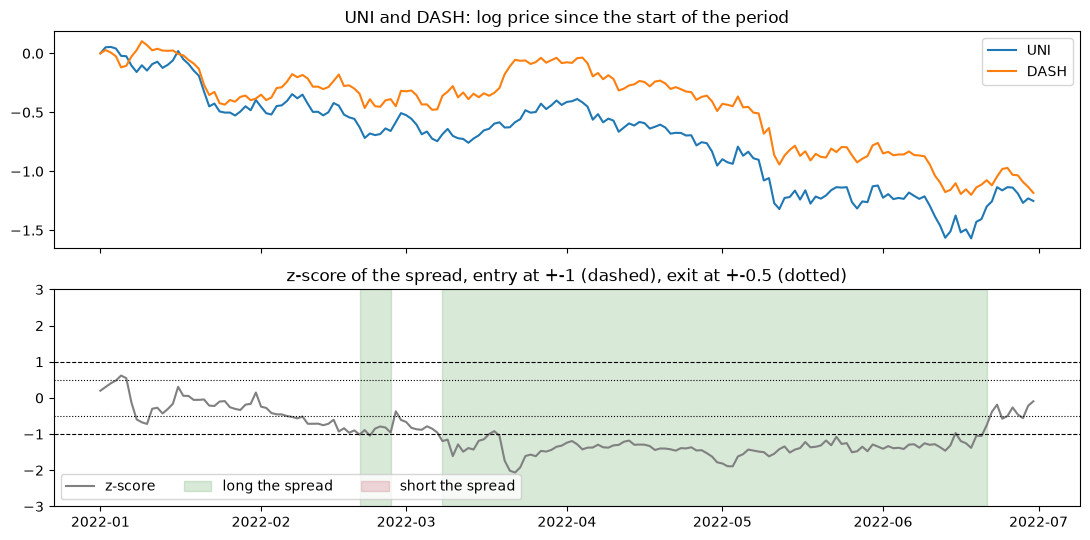

In [6]:
first = periods[0]
y, x = first["tests"].loc[first["tests"].set_index(["y", "x"]).index.isin(first["pairs"])].nsmallest(1, "stat")[["y", "x"]].iloc[0]
z, _ = zscores([(y, x)], first["start"], first["end"])
z, pos = z[0], positions(z)[0]

fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for coin in (y, x):
    ax[0].plot(np.log(px.loc[z.index, coin] / px.loc[z.index[0], coin]), label=coin)
ax[0].set(title=f"{y} and {x}: log price since the start of the period")
ax[0].legend()
ax[1].plot(z, color="grey", label="z-score")
for level, style in ((ENTRY, "--"), (EXIT, ":")):
    ax[1].axhline(level, color="black", ls=style, lw=0.8)
    ax[1].axhline(-level, color="black", ls=style, lw=0.8)
ax[1].fill_between(z.index, -3, 3, where=pos > 0, color="#66aa66", alpha=0.25, label="long the spread")
ax[1].fill_between(z.index, -3, 3, where=pos < 0, color="#cc6677", alpha=0.25, label="short the spread")
ax[1].set(title="z-score of the spread, entry at +-1 (dashed), exit at +-0.5 (dotted)", ylim=(-3, 3))
ax[1].legend(loc="lower left", ncol=3)
plt.tight_layout()

**What the plot shows.** UNI and DASH fall together in early 2022. In late February a short
trade opens and closes within days: the textbook case. Then in early March z drops below -1
and stays between -1 and -2 for three and a half months. The position waits the whole time,
and only in late June does z come back above -0.5 and the trade closes, for a gain of about
0.7σ. It worked out in the end, but one trade held the capital for most of the period. With a
fixed $\beta$ that's what waiting for the leash looks like: z only comes back if the spread does.

## Step 3: the backtest

The 6-month blocks are stitched into one portfolio. A pair dropped at a refit is closed and pays its cost.

In [7]:
def backtest(weights, cost_bps=COST_BPS):
    """Daily returns: yesterday's weights times today's coin returns, minus turnover times cost."""
    rets = px[weights.columns].pct_change().reindex(weights.index).fillna(0)
    gross = (weights.shift() * rets).sum(axis=1)
    turnover = weights.diff().abs().sum(axis=1)
    return pd.DataFrame({"gross": gross, "turnover": turnover, "net": gross - turnover * cost_bps * 1e-4})


def run(periods, **params):
    """Stitch the 6-month blocks together and backtest them as one portfolio. No pairs: no position."""
    days = px.loc[periods[0]["start"]:periods[-1]["end"]].index
    blocks = [coin_weights(p["pairs"], p["start"], p["end"], **params) for p in periods if p["pairs"]]
    return backtest(pd.concat(blocks).fillna(0).reindex(days).fillna(0) if blocks else pd.DataFrame(index=days))


def sharpe(r):
    return r.mean() / r.std() * np.sqrt(365) if r.std() > 0 else np.nan  # nan: nothing was traded


def metrics(r, turnover=None):
    """The scorecard, from daily returns (and turnover, if it is a strategy)."""
    wealth = (1 + r).cumprod()
    drawdown = wealth / wealth.cummax() - 1
    under = drawdown < 0
    beta = r.rolling(365).cov(btc) / btc.rolling(365).var()
    resid = (r - beta.shift() * btc).dropna()  # what is left after taking out BTC exposure
    out = {
        "annual return": r.mean() * 365,
        "annual volatility": r.std() * np.sqrt(365),
        "Sharpe ratio": sharpe(r),
        "max drawdown": drawdown.min(),
        "longest drawdown (days)": under.groupby((~under).cumsum()).sum().max(),
        "correlation with BTC": r.corr(btc),
    }
    if turnover is not None:
        out |= {"information ratio vs BTC": sharpe(resid),
                "turnover per day": turnover.mean(), "holding period (days)": 2 / turnover.mean()}
    return pd.Series(out)


result = run(periods)
btc = px["BTC"].pct_change().reindex(result.index)
net = metrics(result["net"], result["turnover"])
scorecard = pd.DataFrame({
    "strategy, gross": metrics(result["gross"], result["turnover"]),
    "strategy, net": net,
    "buy and hold BTC": metrics(btc),
}).reindex(net.index)
print(f"{result.index[0]:%Y-%m-%d} to {result.index[-1]:%Y-%m-%d}, {len(result)} days")
scorecard.round(3)

2022-01-01 to 2026-10-12, 1746 days


,"strategy, gross","strategy, net",buy and hold BTC
annual return,0.172,0.115,0.247
annual volatility,0.273,0.272,0.505
Sharpe ratio,0.632,0.425,0.489
max drawdown,-0.283,-0.314,-0.669
longest drawdown (days),728.000,752.000,769.000
correlation with BTC,0.040,0.041,1.000
information ratio vs BTC,0.732,0.526,NaN
turnover per day,0.078,0.078,NaN
holding period (days),25.622,25.622,NaN


**What the numbers say.**

- **Gross** it earns 17.2% a year with 27.3% volatility, a Sharpe of 0.63.
- **Net** of 20 bps it earns 11.5% a year, a Sharpe of 0.42. The max drawdown is 31%, and the longest stretch below an earlier peak is 752 days.
- A position is held about **26 days**, and turnover is low (0.08 a day), so costs take only about 6% a year.
- **Market neutral:** correlation with BTC is 0.04, and the information ratio against BTC is 0.73 gross. The return doesn't come from riding the market.
- **BTC buy and hold:** Sharpe 0.49, with a 67% drawdown along the way.
- The flat stretch in the chart below (mid 2025 to early 2026) is the filter sitting out: no pair survived.

The next table shows where the return comes from, trade by trade.

### Trade by trade

Every trade, with its profit from step 5 of the maths, $\text{side} \cdot (z_{out} - z_{in}) \cdot \sigma$,
and the cost of opening and closing both legs. In bps of 1 dollar of $y$. Three entry levels,
because a higher entry should mean more profit per trade for the same cost. This is also a
first look at check 2 below.

In [8]:
def trade_list(entry, exit=EXIT):
    """Every trade of every pair. Profit in bps of the y leg: side * (z_out - z_in) * spread std."""
    rows = []
    for p in periods:
        if not p["pairs"]:
            continue
        z, fits = zscores(p["pairs"], p["start"], p["end"])
        pos = positions(z, entry, exit)
        for k in pos:
            s = pos[k]
            for _, held in s.groupby((s != s.shift()).cumsum()):  # one group per stretch of the same position
                side, t0 = held.iloc[0], held.index[0]
                if side == 0:
                    continue
                t1 = s.index[min(s.index.get_loc(held.index[-1]) + 1, len(s) - 1)]  # exit day, or the period end
                profit = side * (z[k][t1] - z[k][t0]) * fits["std"][k] * 1e4
                cost = 2 * (1 + abs(fits["beta"][k])) * COST_BPS  # open and close both legs
                rows.append({"days": (t1 - t0).days, "by signal": s[t1] != side, "profit": profit, "net": profit - cost})
    return pd.DataFrame(rows)


def trade_summary(t):
    worst = t["net"].nsmallest(len(t) // 20)
    return pd.Series({
        "trades": len(t),
        "closed by the exit signal": t["by signal"].mean(),
        "median days held": t["days"].median(),
        "median profit (bps)": t["profit"].median(),
        "median net (bps)": t["net"].median(),
        "winning trades, net": (t["net"] > 0).mean(),
        "average net (bps)": t["net"].mean(),
        "worst 5% of trades, average net (bps)": worst.mean(),
        "average net without the worst 5% (bps)": t["net"].drop(worst.index).mean(),
    })


t = trade_list(ENTRY)
longer = t["days"] > t["days"].median()
print(f"entry {ENTRY}: the longer half of the trades takes {t.loc[longer, 'days'].sum() / t['days'].sum():.0%} of the days in a position. "
      f"Average profit: longer half {t.loc[longer, 'profit'].mean():+.0f} bps, shorter half {t.loc[~longer, 'profit'].mean():+.0f} bps")
pd.DataFrame({f"entry {e}": trade_summary(trade_list(e)) for e in (1.0, 1.5, 2.0)}).round(2)

entry 1.0: the longer half of the trades takes 92% of the days in a position. Average profit: longer half -504 bps, shorter half +1220 bps


,entry 1.0,entry 1.5,entry 2.0
trades,563.00,348.00,248.00
closed by the exit signal,0.71,0.58,0.53
median days held,16.00,38.00,49.50
median profit (bps),979.61,1260.41,1461.97
median net (bps),909.91,1189.02,1383.57
"winning trades, net",0.78,0.71,0.69
average net (bps),285.30,388.42,524.84
"worst 5% of trades, average net (bps)",-8794.00,-9420.13,-9575.45
average net without the worst 5% (bps),760.48,892.19,1038.42


**What the numbers say.**

- **The typical trade is good.** At entry 1 the median trade makes about 910 bps after costs, and 78% of trades win. A higher entry makes each trade bigger (median 1,190 bps at 1.5 and 1,380 at 2), with fewer trades.
- **A few trades are terrible.** The worst 5% lose about 88 log points each, like being short a coin that rises 140%. Without them the average trade makes 760 bps, with them 285.
- **The losers stay the longest.** The longer half of the trades takes 92% of the days in a position and loses 504 bps on average. The shorter half wins 1,220 bps.

So the edge is real per trade, and the broken leashes cost a lot of it. They stay a risk: a pair
that breaks sits in the book until the next refit.

## Was it luck? Four checks

A result can look good, or bad, by accident. Each check asks one question the scorecard can't answer:

1. **Works on new data?**
2. **Works next door?** An edge is usually a hill, not a needle. Moving things a little should not flip the result.
3. **Survives cost?**
4. **Beats a random market?**

### Check 1: works on new data?

Each 6-month block is traded with pairs chosen on the year before, and nothing was tuned
on the results. So every block is a fresh test.

blocks with a positive net return: 5 of 10


,pairs,gross return,net return,BTC return
2022-01,30,0.276,0.246,-0.714
2022-07,59,-0.158,-0.178,-0.107
2023-01,14,-0.114,-0.135,0.671
2023-07,34,0.102,0.074,0.364
2024-01,36,0.210,0.178,0.469
2024-07,5,0.371,0.304,0.465
2025-01,3,0.230,0.194,0.189
2025-07,0,-0.008,-0.010,-0.168
2026-01,1,-0.063,-0.069,-0.342
2026-07,40,-0.023,-0.050,0.354


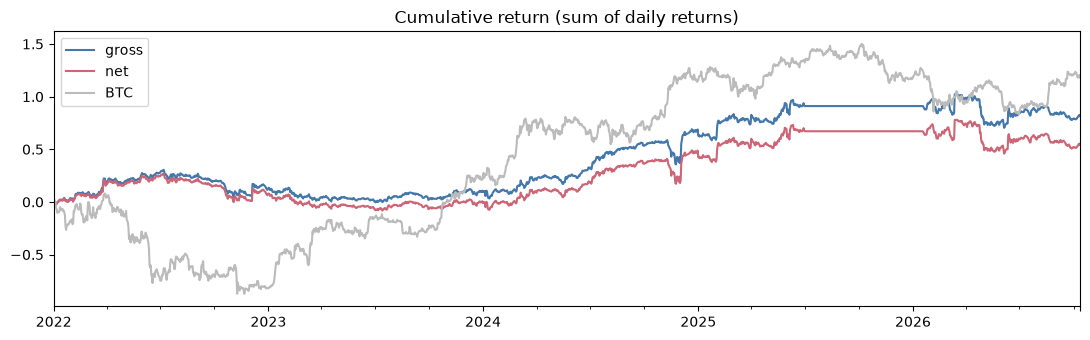

In [9]:
blocks = result.groupby(np.searchsorted([p["end"] for p in periods], result.index))
block_table = pd.DataFrame({
    "pairs": [len(p["pairs"]) for p in periods],
    "gross return": blocks["gross"].sum().values,
    "net return": blocks["net"].sum().values,
    "BTC return": btc.groupby(np.searchsorted([p["end"] for p in periods], btc.index)).sum().values,
}, index=[f"{p['start']:%Y-%m}" for p in periods])
print(f"blocks with a positive net return: {(block_table['net return'] > 0).sum()} of {len(block_table)}")
display(block_table.round(3))

ax = result[["gross", "net"]].assign(BTC=btc).cumsum().plot(figsize=(11, 3.5), color=["#4477aa", "#cc6677", "#bbbbbb"])
ax.set(title="Cumulative return (sum of daily returns)", xlabel="")
plt.tight_layout()

**What the numbers say.** 5 of 10 blocks are positive, and the gains are uneven. July 2024
(5 pairs, +30% net) and January 2025 (3 pairs, +19%) carry a large part of the result. July 2025
trades nothing, and January 2026 trades a single pair. So the result holds on new data, but in some
periods it rests on very few pairs.

### Check 2: works next door?

**Settings.** Entry 0.75 / 1 / 1.5, exit 0.2 / 0.5 / 0.7. The whole grid is shown. The best
cell is never the result, because picking the best of 9 is the same trap as picking the best of 4,950 pairs.

gross Sharpe across the 9 settings: median 0.60, range 0.37 to 0.87, positive in 9 of 9
net Sharpe across the 9 settings: median 0.39, range 0.24 to 0.51, positive in 9 of 9


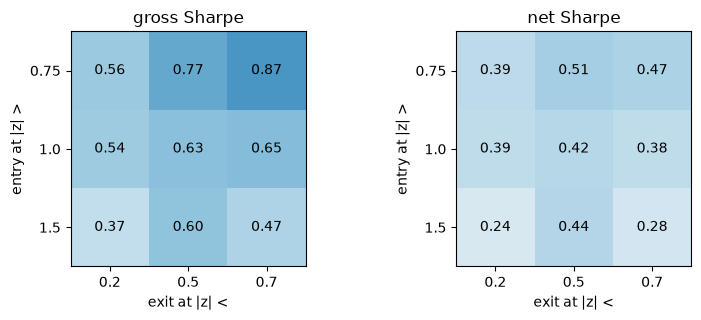

In [10]:
grid = []
for entry in (0.75, 1.0, 1.5):
    for exit in (0.2, 0.5, 0.7):
        r = run(periods, entry=entry, exit=exit)
        grid.append({"entry": entry, "exit": exit, "gross": sharpe(r["gross"]), "net": sharpe(r["net"])})
grid = pd.DataFrame(grid)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.3))
for ax, col in zip(axes, ["gross", "net"]):
    table = grid.pivot(index="entry", columns="exit", values=col)
    ax.imshow(table, cmap="RdBu", vmin=-1.5, vmax=1.5)
    for (i, j), v in np.ndenumerate(table.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center")
    ax.set(title=f"{col} Sharpe", xticks=range(3), xticklabels=table.columns,
           yticks=range(3), yticklabels=table.index, xlabel="exit at |z| <", ylabel="entry at |z| >")
plt.tight_layout()
for col in ("gross", "net"):
    print(f"{col} Sharpe across the 9 settings: median {grid[col].median():.2f}, "
          f"range {grid[col].min():.2f} to {grid[col].max():.2f}, positive in {(grid[col] > 0).sum()} of 9")

**What the numbers say.** This time it's a hill: all 9 settings are positive, gross (0.37 to 0.87)
and net (0.24 to 0.51). The fixed setting (0.63 gross) sits in the middle, so it wasn't a lucky
pick. The trade table above says the same from another angle: a higher entry makes each trade
bigger without flipping the result.

**Time and coins.** Sharpe per year, and the strategy run on the top 50 and on coins 51 to 100 separately.

In [11]:
by_year = result.groupby(result.index.year)
display(pd.DataFrame({"gross Sharpe": by_year["gross"].apply(sharpe), "net Sharpe": by_year["net"].apply(sharpe),
                      "BTC Sharpe": btc.groupby(btc.index.year).apply(sharpe)}).round(2).T)

halves = {}
for name, ranks in {"top 50": slice(0, 50), "coins 51 to 100": slice(50, 100)}.items():
    sub = []
    for p in periods:
        group = p["coins"][ranks]
        tests = p["tests"][p["tests"]["y"].isin(group) & p["tests"]["x"].isin(group)]
        sub.append(p | {"pairs": pick_pairs(tests)})
    r = run(sub)
    halves[name] = {"gross Sharpe": sharpe(r["gross"]), "net Sharpe": sharpe(r["net"]),
                    "pairs per block": np.mean([len(p["pairs"]) for p in sub])}
pd.DataFrame(halves).round(2)

date,2022,2023,2024,2025,2026
gross Sharpe,0.49,-0.07,1.88,0.84,-0.30
net Sharpe,0.28,-0.38,1.56,0.70,-0.42
BTC Sharpe,-1.29,2.35,1.76,0.05,0.03


,top 50,coins 51 to 100
gross Sharpe,-0.09,0.54
net Sharpe,-0.22,0.41
pairs per block,6.60,4.10


**What the numbers say.** 3 of 5 years are positive, gross and net: 2022, 2024 (1.88 gross) and
2025. 2023 and 2026 are slightly negative. By coins, the smaller half carries it: coins 51 to 100
make 0.54 gross (0.41 net), the top 50 about nothing (-0.09). With only 4 to 7 pairs per block in
each half, that split is a rough guide, not a firm result.

### Check 3: survives cost?

The same gross returns with costs from 0 to 40 bps.

In [12]:
costs = [0, 5, 10, 20, 30, 40]
sweep = pd.DataFrame({
    "net Sharpe": [sharpe(result["gross"] - result["turnover"] * c * 1e-4) for c in costs],
    "net annual return": [(result["gross"] - result["turnover"] * c * 1e-4).mean() * 365 for c in costs],
}, index=pd.Index(costs, name="cost (bps)"))
breakeven = result["gross"].mean() / result["turnover"].mean() * 1e4
print(f"breakeven cost: {breakeven:.1f} bps per unit of turnover")
sweep.round(3)

breakeven cost: 60.5 bps per unit of turnover


,net Sharpe,net annual return
cost (bps),,
0,0.632,0.172
5,0.581,0.158
10,0.529,0.144
20,0.425,0.115
30,0.320,0.087
40,0.216,0.058


**What the numbers say.** The breakeven cost is 60.5 bps per unit of turnover, three times the
assumed 20. At 40 bps the net Sharpe is still 0.22. A Binance spot fee is about 10 bps, so there is
room for slippage and for the shorting cost that isn't modelled. Of the four checks, this one is
the clearest.

### Check 4: beats a random market?

A random market is one with no edge in it by construction. I take the real daily returns of
all coins and shuffle the order of the days, the same shuffle for every coin. That keeps each
coin's volatility, its pumps and crashes, and how coins move together on the same day. It
destroys everything that depends on order: trends, reversion, cointegration.

Then the whole pipeline runs on it, search and filter included, 10 times. The filter has to run
too, because it is part of the strategy: any luck it lets through on real data, it lets through
here as well. About 30 minutes, so 10 runs give a rough range.

In [13]:
def shuffled_prices(prices, seed):
    """The real daily returns, with the days in a random order (the same order for every coin)."""
    rets = np.log(prices).diff()
    order = np.random.default_rng(seed).permutation(len(rets))
    shuffled = rets.copy()
    for coin in rets:
        live = rets[coin].notna().to_numpy()  # only the days the coin actually traded
        shuffled.loc[live, coin] = rets[coin][live].to_numpy()[np.argsort(order[live])]
    return np.exp(shuffled.fillna(0).cumsum()).where(prices.notna())


real_px, luck = px, []
for seed in range(10):
    px = shuffled_prices(real_px, seed)  # every function below now sees the shuffled market
    fake = search()
    r = run(fake)
    luck.append({"gross Sharpe": sharpe(r["gross"]), "net Sharpe": sharpe(r["net"]),
                 "pairs passing per period": np.mean([(p["tests"]["p"] < ALPHA).sum() for p in fake]),
                 "pairs traded per period": np.mean([len(p["pairs"]) for p in fake])})
px = real_px
luck = pd.DataFrame(luck)

print(f"real market: gross Sharpe {sharpe(result['gross']):.2f}, net Sharpe {sharpe(result['net']):.2f}")
luck.describe().loc[["mean", "min", "max"]].round(2)

real market: gross Sharpe 0.63, net Sharpe 0.42


,gross Sharpe,net Sharpe,pairs passing per period,pairs traded per period
mean,-0.05,-0.08,314.98,2.64
min,-0.65,-0.67,248.10,0.00
max,0.69,0.66,376.80,7.60


**What the numbers say.** On the shuffled markets the filter mostly finds nothing: 2.6 pairs per
period on average, against 0 to 59 on the real market. The gross Sharpe of the shuffled runs goes
from -0.65 to 0.69 (average -0.05). The real 0.63 is near the top of that range. One shuffled
market got 0.69 from a handful of lucky pairs, which shows how much a few pairs can swing a result.

## The four checks together

| Check | Question | Result |
|---|---|---|
| 1. New data | Do the fresh 6-month blocks make money? | 5 of 10, with two blocks of 3 to 5 pairs carrying much of it |
| 2. Next door | Do nearby settings, years and coins agree? | All 9 settings positive, gross and net. 3 of 5 years. Mostly coins 51 to 100 |
| 3. Cost | Does it survive 20 bps? | Yes. Breakeven 60.5 bps, net Sharpe 0.22 even at 40 bps |
| 4. Random market | Better than shuffled markets with no edge? | 0.63, near the top of the luck range (-0.65 to 0.69) |

## Conclusion

Pairs trading on the 100 most traded coins, with a Benjamini-Hochberg filter on the search, earns
11.5% a year after 20 bps of costs (net Sharpe 0.42), market neutral, over almost five years of
out-of-sample data. **It's a tradable strategy as long as the real all-in cost per unit traded,
including the cost of shorting, stays below the breakeven of about 60 bps.**

What makes it work, and what to watch:

- **The filter does the heavy lifting.** Without it, the strategy trades every lucky pass and earns nothing. With it, it only trades pairs whose test result stands out from the luck, and sits out when there are none.
- **The mechanism is visible per trade.** With fixed $\alpha$, $\beta$, $\sigma$, a trade earns exactly $\text{side} \cdot (z_{out} - z_{in}) \cdot \sigma$. The median trade makes about 910 bps after costs, and 78% of trades win.
- **Broken leashes are the main risk.** The worst 5% of trades lose about 88 log points each, and they stay in the book the longest.

This is a research result on daily data, not a live track record. How the design got here is in the last section.

## Afterwards: how the design got here

The strategy above is the end of a few rounds of: look at where it fails, think of a fix, test it,
keep it or drop it. Every row is judged the same way, and the details are in
`experiments/2_variants.ipynb`.

| Step | Why I tried it | Gross Sharpe | Net Sharpe | Breakeven (bps) | Kept? |
|---|---|---|---|---|---|
| Dynamic $\beta$ (rolling 90 days), all pairs with p < 0.05 | The textbook version | 0.20 | -0.58 | 5.1 | No: z can fall back without the spread coming back |
| Static $\beta$, all pairs | Trade exactly the relationship that was tested | 0.01 | -0.27 | 0.7 | Yes, the static $\beta$ |
| Static $\beta$, entry 1.5 / 2 | More profit per trade for the same cost | -0.21 / -0.34 | -0.43 / -0.53 | below 0 | No: fewer trades, more of them broken |
| Break alarm at 25% / 50% / 100% | The losers are broken leashes, so close them early | -0.39 / 0.49 / 0.14 | -0.71 / 0.06 / -0.23 | below 0 / 23 / 8 | No: nearby limits disagree, so the 50% result is likely luck |
| BH filter at 1% / 10% | Neighbours of the 5% level | 0.71 / 0.15 | 0.60 / -0.07 | 116 / 14 | Stricter is better, as expected if the filter removes lucky pairs |
| **BH filter at 5% (this paper)** | Most passes in the search are luck | **0.63** | **0.42** | **60.5** | **Yes** |

The break alarm runs a 90 day rolling $\beta$ next to the frozen one and closes a pair for good once
the two drift more than the limit apart. The BH level of 5% was set before these tests (it is the
level in the search table), so it is the design choice, and 1% and 10% are its next-door check.

## What this is not

- Not a live track record. It's a backtest on daily closes, with costs as one flat assumption.
- Shorting costs (margin interest or futures funding) are not modelled, and delisted coins are missing. Both would lower the result. The breakeven of 60.5 bps is the room for them.
- In some periods only a handful of pairs are traded, so a few trades carry a lot of weight.
- Daily closes miss anything that happens within a day.